In [18]:
'''Fine-tune gradient boosting models (LightGBM, CatBoost, XGBoost) 
by optimizing learning rates, regularization parameters, and tree structures,
ensuring robust generalization across validation folds.'''

'Fine-tune gradient boosting models (LightGBM, CatBoost, XGBoost) \nby optimizing learning rates, regularization parameters, and tree structures,\nensuring robust generalization across validation folds.'

In [19]:
import pandas as pd
import numpy as np

df = pd.read_csv("global_pharmacy_sales_data.csv")

# convert date into proper date format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# remove rows with missing important values
df = df.dropna(subset=["date", "units_sold", "unit_price"])

# calculate total sales value
df["sales_value"] = df["units_sold"] * df["unit_price"]

# sort records by date for realistic validation
df = df.sort_values("date").reset_index(drop=True)

# display basic information
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (177990, 15)

Columns:
['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'sales_value']

Missing values:
date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
sales_value              0
dtype: int64


In [20]:
# choose the columns that will be used for prediction
drop_cols = ["date", "units_sold", "unit_price", "sales_value"]

X = df.drop(columns=drop_cols)
y = df["sales_value"]

# identify categorical and numerical columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)
print("Target column: sales_value")

Categorical columns: ['region', 'country', 'category', 'medicine', 'age_group']
Numerical columns: ['year', 'month', 'day', 'stock_level', 'expiry_days_remaining', 'covid_flag']
Target column: sales_value


In [21]:
# use earlier records for training and later records for testing
split = int(len(df) * 0.80)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training ends:", df["date"].iloc[split - 1])
print("Testing starts:", df["date"].iloc[split])


Training records: 142392
Testing records: 35598
Training ends: 2024-10-19 00:00:00
Testing starts: 2024-10-19 00:00:00


In [22]:
# import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# fill missing numerical values
num_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="median"))
])

# fill missing categories and convert them into numeric columns
cat_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

# apply the correct preparation to each column type
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

In [23]:
# import the three boosting algorithms
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

# create the base models
models = {
    "LightGBM": LGBMRegressor(
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),

    "CatBoost": CatBoostRegressor(
        random_seed=42,
        verbose=0,
        thread_count=-1,
        allow_writing_files=False
    ),

    "XGBoost": XGBRegressor(
        random_state=42,
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        n_jobs=-1
    )
}

print("LightGBM, CatBoost and XGBoost are ready.")

LightGBM, CatBoost and XGBoost are ready.


In [24]:
#define the hyperparameter search space
# define the parameters to test for each model
param_grids = {
    "LightGBM": {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__n_estimators": [200, 400],
        "model__max_depth": [5, 8, -1],
        "model__num_leaves": [15, 31, 50],
        "model__min_child_samples": [20, 40],
        "model__reg_alpha": [0, 0.5, 1],
        "model__reg_lambda": [1, 5, 10]
    },

    "CatBoost": {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__iterations": [200, 400],
        "model__depth": [4, 6, 8],
        "model__l2_leaf_reg": [3, 5, 9],
        "model__random_strength": [0.5, 1, 2]
    },

    "XGBoost": {
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__n_estimators": [200, 400],
        "model__max_depth": [3, 5, 7],
        "model__min_child_weight": [1, 3, 5],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
        "model__reg_alpha": [0, 0.5, 1],
        "model__reg_lambda": [1, 5, 10]
    }
}

print("Hyperparameter search spaces defined.")

Hyperparameter search spaces defined.


In [25]:
#fine-tune models using five validation folds
# import model tuning and validation tools
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
import time

# create five time-based validation folds
tscv = TimeSeriesSplit(n_splits=5)

# store the best model and its results
best_models = {}
results = []

# tune each boosting model
for name, model in models.items():

    print("\nTuning", name)

    # combine data preparation and model into one pipeline
    pipe = Pipeline([
        ("prep", clone(preprocessor)),
        ("model", model)
    ])

    # search for the best parameter combination
    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_grids[name],
        n_iter=4,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        random_state=42,
        n_jobs=1,
        verbose=1,
        refit=True,
        error_score="raise"
    )

    # measure tuning time
    start = time.time()

    # train and compare parameter combinations
    search.fit(X_train, y_train)

    elapsed = time.time() - start

    # save the best fitted model
    best_models[name] = search.best_estimator_

    # display the best parameters and validation score
    print("Best parameters:", search.best_params_)
    print("Best CV RMSE:", round(-search.best_score_, 2))
    print("Time taken:", round(elapsed, 2), "seconds")

    results.append({
        "Model": name,
        "Best CV RMSE": -search.best_score_,
        "Best Parameters": search.best_params_,
        "Time (seconds)": elapsed
    })

print("\nAll models have been tuned.")


Tuning LightGBM
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__reg_lambda': 1, 'model__reg_alpha': 0, 'model__num_leaves': 15, 'model__n_estimators': 200, 'model__min_child_samples': 40, 'model__max_depth': -1, 'model__learning_rate': 0.03}
Best CV RMSE: 15524.88
Time taken: 13.97 seconds

Tuning CatBoost
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__random_strength': 1, 'model__learning_rate': 0.03, 'model__l2_leaf_reg': 3, 'model__iterations': 200, 'model__depth': 6}
Best CV RMSE: 15564.27
Time taken: 42.85 seconds

Tuning XGBoost
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__reg_alpha': 0.5, 'model__n_estimators': 200, 'model__min_child_weight': 3, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Best CV RMSE: 15596.49
Time taken: 27.43 seconds

All models have been tuned.


In [26]:
#evaluate and compare the tuned models
# store the final evaluation results
final_results = []

# evaluate every tuned model
for name, model in best_models.items():

    # predict on training and unseen test records
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # calculate performance metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    test_r2 = r2_score(y_test, test_pred)

    # store the results for comparison
    final_results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Test R2": test_r2,
        "RMSE Gap": test_rmse - train_rmse
    })

# display the models from lowest to highest validation error
comparison = pd.DataFrame(final_results)
comparison = comparison.sort_values("Test RMSE").reset_index(drop=True)

print("Final Model Comparison:")
print(comparison.round(3).to_string(index=False))

# select the model with the lowest test RMSE for reporting
best_name = comparison.loc[0, "Model"]

print("\nBest model by test RMSE:", best_name)

Final Model Comparison:
   Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Test R2  RMSE Gap
CatBoost   16505.016  12821.490  11544.492  9175.314    0.487 -3683.526
LightGBM   16271.931  12982.905  11512.575  9188.690    0.474 -3289.025
 XGBoost   15977.093  13006.382  11456.496  9180.863    0.472 -2970.711

Best model by test RMSE: CatBoost


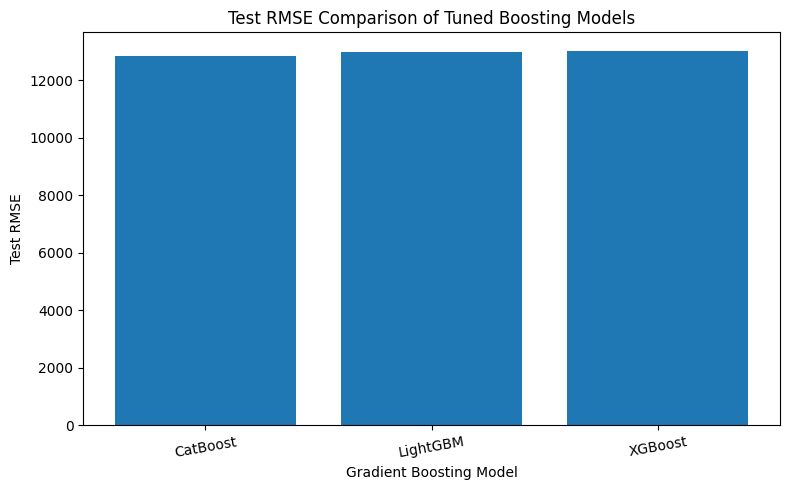

In [27]:
#visualize model performance
# import plotting library
import matplotlib.pyplot as plt

# compare test RMSE for each model
plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["Test RMSE"])

plt.title("Test RMSE Comparison of Tuned Boosting Models")
plt.xlabel("Gradient Boosting Model")
plt.ylabel("Test RMSE")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

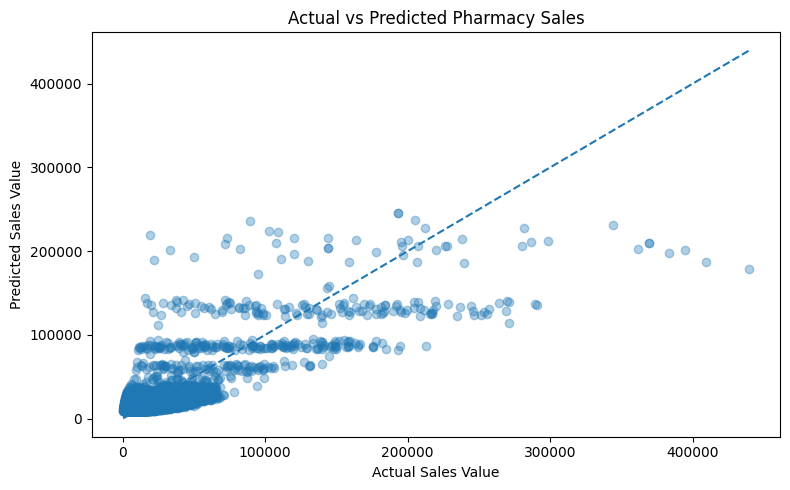

In [28]:
#Check actual versus predicted sales
# get predictions from the selected model
best_model = best_models[best_name]
predictions = best_model.predict(X_test)

# plot actual and predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions, alpha=0.35)

# draw a reference line for perfect predictions
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], linestyle="--")

plt.title("Actual vs Predicted Pharmacy Sales")
plt.xlabel("Actual Sales Value")
plt.ylabel("Predicted Sales Value")
plt.tight_layout()
plt.show()

In [29]:
# select the model using cross-validation results
cv_results = pd.DataFrame(results)

best_name = cv_results.loc[
    cv_results["Best CV RMSE"].idxmin(), "Model"
]

best_model = best_models[best_name]

print("Best model based on CV RMSE:", best_name)
print("Best CV RMSE:", round(
    cv_results.loc[
        cv_results["Model"] == best_name, "Best CV RMSE"
    ].iloc[0], 3
))

Best model based on CV RMSE: LightGBM
Best CV RMSE: 15524.88
